# CsI–SiPM：电荷重新分箱与多时间尺度波动约束

2026-11-02。按用户要求，先将[上一轮固定雪崩历史的噪声重放](codex_0001_csi_noise_replay.ipynb)用英文提交为 **ddd6ca7**（`Audit CsI PID selection and fixed-history noise fluctuations`），随后push并用GitHub main提交号核对一致，再开展本轮分析。

上一轮取消事件方差CV后，Co F202宽度接近实测，但F50明显过窄。本轮先检验这个矛盾是否受电荷选择影响，再给下一轮模型提供跨尺度约束。**新增独立Geant4母事件、读出重放及实验事件均为0**；全部复用已封存的原ADC特征和16次正编号读出。

本轮不修改ADC，不拟合或升级参数，不更新正式PID或实验ROC。已用数据都参与过探索，不能称为盲验证。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/charge_scales_20261102'
def read(p):return json.loads(Path(p).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.4g}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');points=read(OUT/'point_analysis.json');repeats=read(OUT/'repeat_analysis.json');d=read(OUT/'decision.json')
display(Markdown('**本轮结论：**'+d['conclusion_zh']))
for x in d['findings_zh']:display(Markdown(x))
print('冻结提交:',p['checkpoint_commit'],'核对输入:',len(p['inputs_sha256']))

冻结提交: ddd6ca7c7eb7a08d567efc19745c2560ad176904 核对输入: 505


**本轮结论：**已完成原电荷与当前电荷的配对敏感性、多尺度协方差和方差直线诊断；没有修改波形、参数或正式PID。至少一个源的短、长尺度要求在该条件方差直线上存在明确差异，不能用这条单方向插值直接选定统一响应。

**Co60，晚段块128、16次读出：**按当前电荷重新分箱后，当前响应F202 SD比由1.250 [1.206, 1.337]变为1.253 [1.210, 1.340]；F50由0.970 [0.894, 1.035]变为0.972 [0.895, 1.036]。

**Co60，当前电荷条件下零CV：**F202 SD比为1.026 [0.991, 1.096]，F50 SD比为0.636 [0.585, 0.679]。

**Co60，方差直线诊断：**λ50=1.102 [0.880, 1.435]，λ202=-0.102 [-0.333, 0.038]；配对差λ50−λ202=1.204 [0.961, 1.672]。λ只描述两个已算对照的方差端点，不是器件CV。

**Am241，晚段块128、16次读出：**按当前电荷重新分箱后，当前响应F202 SD比由1.210 [1.147, 1.308]变为1.204 [1.141, 1.305]；F50由0.979 [0.923, 1.051]变为0.972 [0.917, 1.043]。

**Am241，当前电荷条件下零CV：**F202 SD比为1.173 [1.114, 1.271]，F50 SD比为0.902 [0.854, 0.970]。

**Am241，方差直线诊断：**λ50=1.427 [0.417, 2.375]，λ202=-5.092 [-7.568, -3.559]；配对差λ50−λ202=6.519 [4.531, 9.350]。λ只描述两个已算对照的方差端点，不是器件CV。

## 1. 明确区分原电荷与当前电荷

实测原Q就是当前波形的积分电荷；模拟之前统一继承冻结ADC的原Q，响应或噪声改变后仍不重新分箱。现在固定原事件队列、响应折、Q范围、Q半箱物理阈值和目标质量，比较三种条件：

|条件|参与事件|分箱和半箱权重|
|---|---|---|
|original_Q|原支持Q箱中的原事件|沿用原Q|
|retained_original_Q|当前Q仍在该源支持内，同时保留原Q支持|按原Q重权，用于检查移出支持的影响|
|current_Q|原队列中当前Q落入该源支持的事件|按当前Q重权，也允许原先处于非支持箱的已有事件进入|

Co支持原6箱，Am支持前3箱。上下溢出单列，最高总电荷边界包含，不能把越界值强行夹到边箱。每个原Q支持箱及正目标半箱都必须存在；某次抽样缺格则整体不可估计，不能删除该箱。

积分门1520个整数ADC样点，基线为前128点整数ADC的均值，故$Q=\sum ADC-1520\sum ADC_{pre}/128$严格落在1/8 ADC网格。由76个20点均值恢复Q后，仅恢复这一精确网格，并要求浮点残差<10⁻⁷，避免中位数阈值恰好相等时被舍入误差分到另一半箱。所有正编号读出的恢复Q与原生保存的`qcalc`逐条相等；实测恢复Q与原Q逐条相等。

**原电荷范围之外的母事件不在这个已选队列内，无法通过本轮重新分箱补回。** 因此三种结果都是有限队列内的敏感性，不是完整触发、质量选择或探测效率验证。


|源|响应|原支持|当前支持|移出|移入|换箱|下溢|上溢|
|---|---|---|---|---|---|---|---|---|
|Co60|current|2175|2118|56.62|0|301.9|21.38|35.25|
|Co60|zero_cv|2175|2118|56.88|0|302|21.56|35.31|
|Am241|current|1406|1348|89|31.5|485.8|53.56|0|
|Am241|zero_cv|1406|1348|89.06|31.5|486|53.56|0|

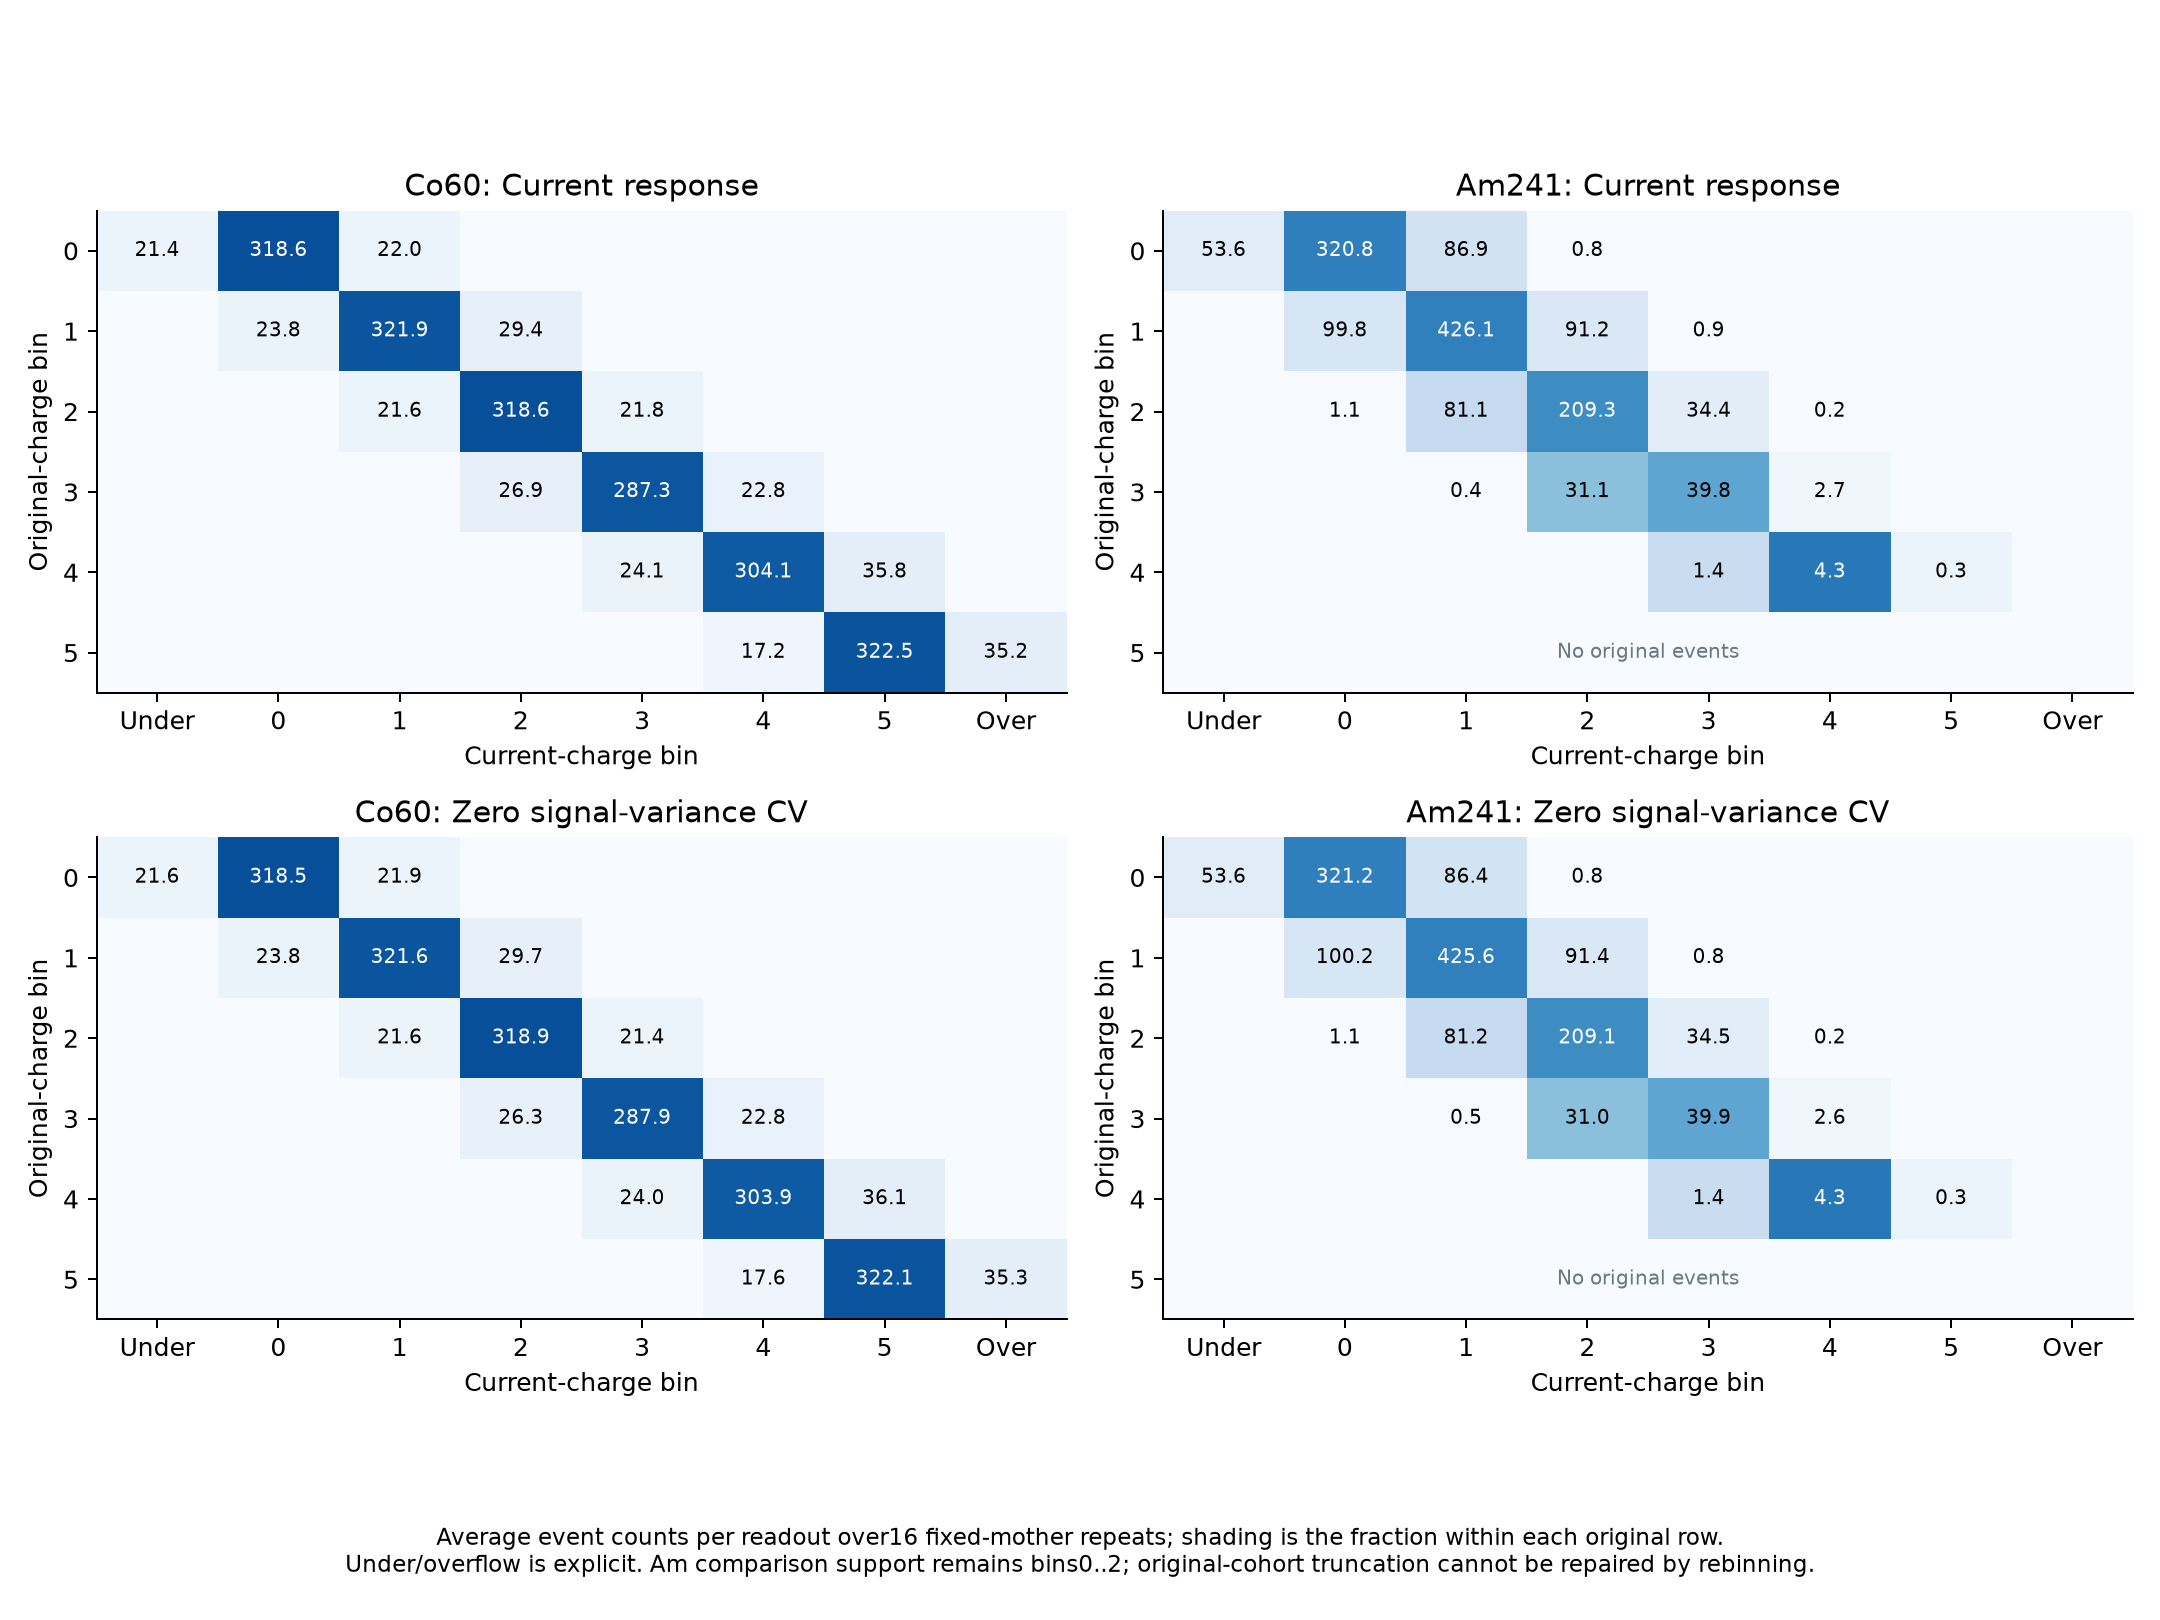

{'exact_integer_ADC_charge_examples': 100,
 'boundary_cases': 7,
 'orthonormal_rotation': True,
 'independent_weighted_covariance_cells': 2,
 'trace_preserved': True,
 'missing_support_propagated': True,
 'degenerate_interpolation_is_unestimable': True}

In [2]:
rows=[]
for source,g in repeats.items():
    for v,items in g['migration'].items():
        means={n:np.mean([x[n] for x in items]) for n in ['old_support','current_support','leave_support','enter_support','bin_changed','underflow','overflow']}
        rows.append([source,v,*[fmt(means[n]) for n in means]])
display(Markdown(table(['源','响应','原支持','当前支持','移出','移入','换箱','下溢','上溢'],rows)))
display(Image(filename=str(OUT/'figures/charge_migration.png')))
display(read(OUT/'algebra_tests.json'))

## 2. 按每次读出重新加权，再比较波动宽度

主要条件为晚段、块128、当前扩展谱响应及零CV对照的16次正编号读出。每次读出分别按指定Q条件计算箱内协方差、均值、中心50%/95%宽度平方、平均ADC，然后跨读出平均；宽度最终开平方。这样保留“一次读出实验”的统计对象。

512次配对抽样沿用原实验索引块和完整母事件计数；一个母事件的16条读出始终一起抽取。每次重复、每个支持箱都必须有效。**不能把16次读出摊平后当成16倍独立母事件**，也不能在电荷权重依赖噪声时直接使用上一轮固定权重的母事件内/间分解。区间固定已生成的读出及参考，未完整计入有限重复的噪声积分误差；前8/后8对照保留用于检查敏感性。

原Q条件的单次结果逐次闭合上一轮512组对比，重复结果闭合上一轮“一次读出经验协方差的重复平均”；这里没有将其混同于另一个有限重复校正估计。


|源|Q条件|响应|F50 SD比|F102 SD比|F202 SD比|F202条件95%范围|
|---|---|---|---|---|---|---|
|Co60|original_Q|current|0.9704|1.175|1.25|[1.206, 1.337] (512/512)|
|Co60|original_Q|zero_cv|0.6363|0.8243|1.026|[0.9901, 1.095] (512/512)|
|Co60|retained_original_Q|current|0.9706|1.177|1.252|[1.208, 1.338] (512/512)|
|Co60|retained_original_Q|zero_cv|0.6358|0.8246|1.027|[0.9912, 1.096] (512/512)|
|Co60|current_Q|current|0.9719|1.179|1.253|[1.21, 1.34] (512/512)|
|Co60|current_Q|zero_cv|0.6362|0.8248|1.026|[0.9908, 1.096] (512/512)|
|Am241|original_Q|current|0.9786|1.087|1.21|[1.147, 1.308] (512/512)|
|Am241|original_Q|zero_cv|0.9067|1.034|1.178|[1.12, 1.272] (512/512)|
|Am241|retained_original_Q|current|0.9707|1.081|1.205|[1.142, 1.306] (512/512)|
|Am241|retained_original_Q|zero_cv|0.9006|1.028|1.173|[1.115, 1.27] (512/512)|
|Am241|current_Q|current|0.9716|1.081|1.204|[1.141, 1.305] (512/512)|
|Am241|current_Q|zero_cv|0.9017|1.029|1.173|[1.114, 1.271] (512/512)|

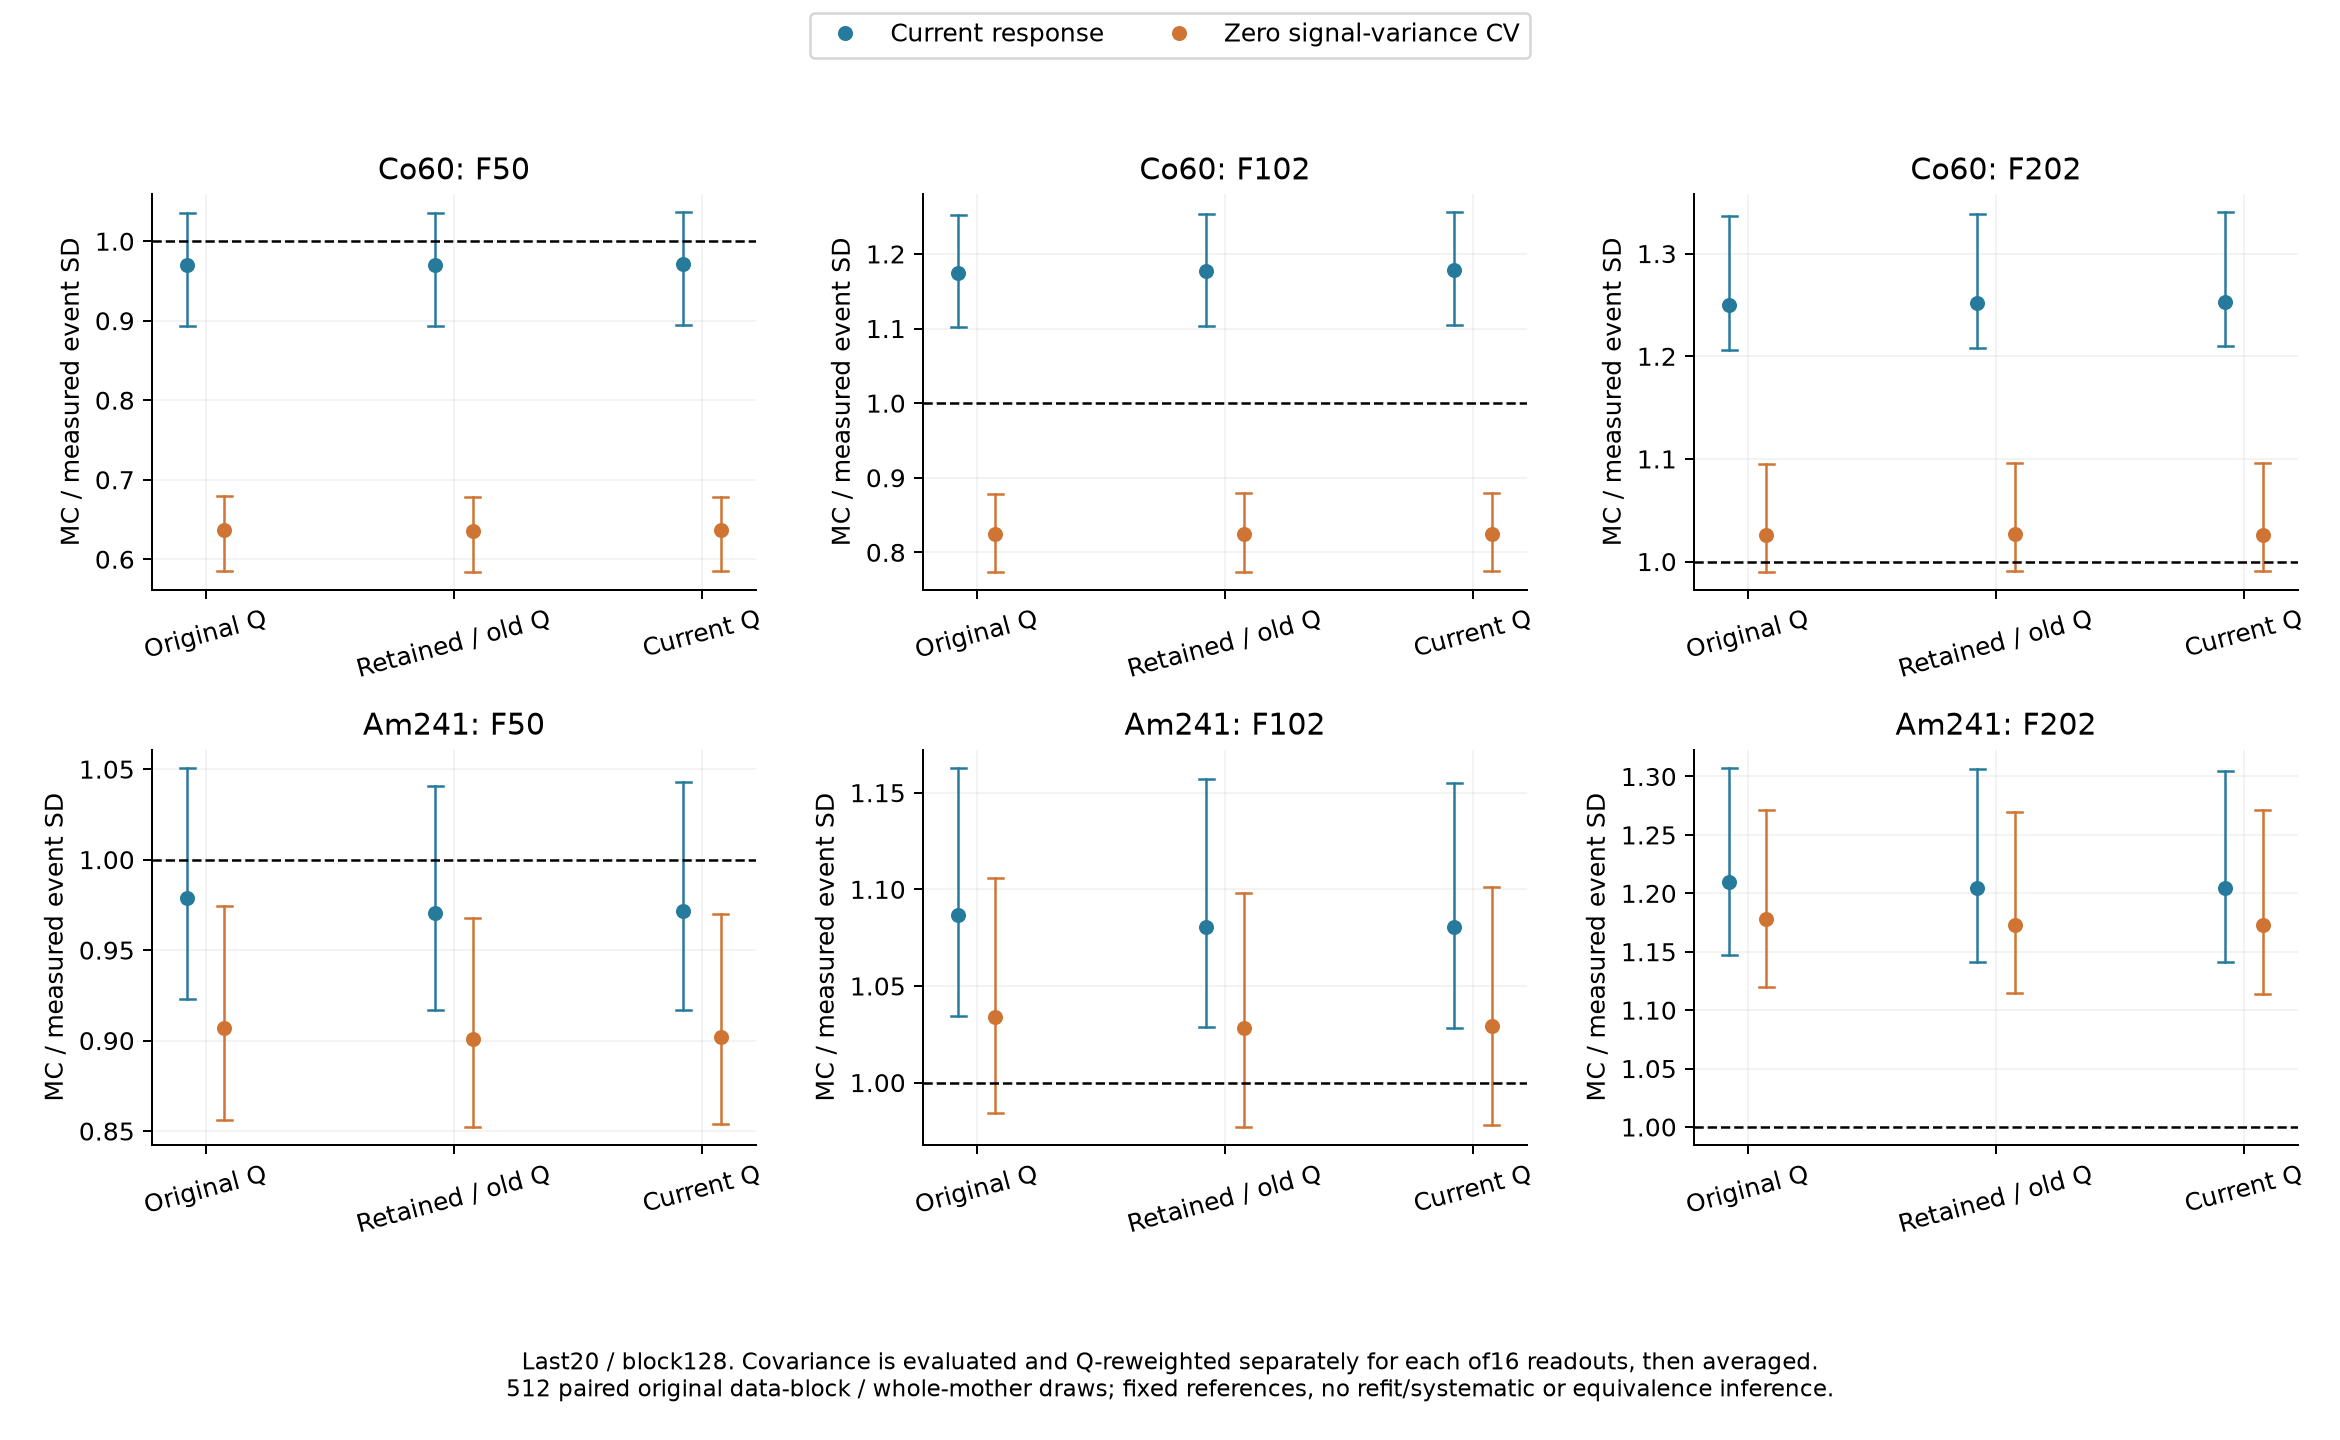

In [3]:
rows=[]
for source,g in repeats.items():
    for c,item in g['conditions'].items():
        for v,r in item['variants'].items():
            rows.append([source,c,v,*[fmt(r['point'][f'F{s}_SD_ratio']) for s in [50,102,202]],ci(r['CI95']['F202_SD_ratio'])])
display(Markdown(table(['源','Q条件','响应','F50 SD比','F102 SD比','F202 SD比','F202条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/charge_width_controls.png')))

## 3. 三个尺度的协方差与差分组合

各原评价折/Q箱采用对折实测的加权均值$m_s$，定义$z_s=F_s/m_s-1$。参考在本轮抽样中固定；当前Q条件选用当前箱的参考。再作固定正交变换：

\[
u_c=(z_{50}+z_{102}+z_{202})/\sqrt3,\quad
u_d=(z_{50}-z_{202})/\sqrt2,\quad
u_k=(z_{50}-2z_{102}+z_{202})/\sqrt6.
\]

这三个轴分别描述共同起伏、短长差异和中间尺度的相对弯曲。正交变换保持规范化协方差的迹，但**不会让物理噪声变成互相独立的频带**。F50/F102/F202来自重叠滤波统计，本来就相关；相关系数、各轴方差与完整协方差误差应共同检查。对折规范化也不使已探索实验重新成为独立验证数据。


|源|响应|联合指标|点值|条件95%范围|
|---|---|---|---|---|
|Co60|current|F_common_SD_ratio|1.15|[1.071, 1.245] (512/512)|
|Co60|current|F_short_long_SD_ratio|0.9251|[0.8176, 0.9955] (512/512)|
|Co60|current|F_curvature_SD_ratio|1.109|[1.034, 1.197] (512/512)|
|Co60|current|F_covariance_relative_error|0.351|[0.282, 0.4761] (512/512)|
|Co60|zero_cv|F_common_SD_ratio|0.7758|[0.7232, 0.8359] (512/512)|
|Co60|zero_cv|F_short_long_SD_ratio|0.9017|[0.7975, 0.97] (512/512)|
|Co60|zero_cv|F_curvature_SD_ratio|1.094|[1.019, 1.181] (512/512)|
|Co60|zero_cv|F_covariance_relative_error|0.345|[0.301, 0.3925] (512/512)|
|Am241|current|F_common_SD_ratio|1.089|[1.043, 1.166] (512/512)|
|Am241|current|F_short_long_SD_ratio|1.141|[1.084, 1.23] (512/512)|
|Am241|current|F_curvature_SD_ratio|1.051|[0.9881, 1.145] (512/512)|
|Am241|current|F_covariance_relative_error|0.1906|[0.129, 0.3063] (512/512)|
|Am241|zero_cv|F_common_SD_ratio|1.025|[0.9813, 1.097] (512/512)|
|Am241|zero_cv|F_short_long_SD_ratio|1.139|[1.083, 1.228] (512/512)|
|Am241|zero_cv|F_curvature_SD_ratio|1.049|[0.9862, 1.141] (512/512)|
|Am241|zero_cv|F_covariance_relative_error|0.1582|[0.1091, 0.2565] (512/512)|

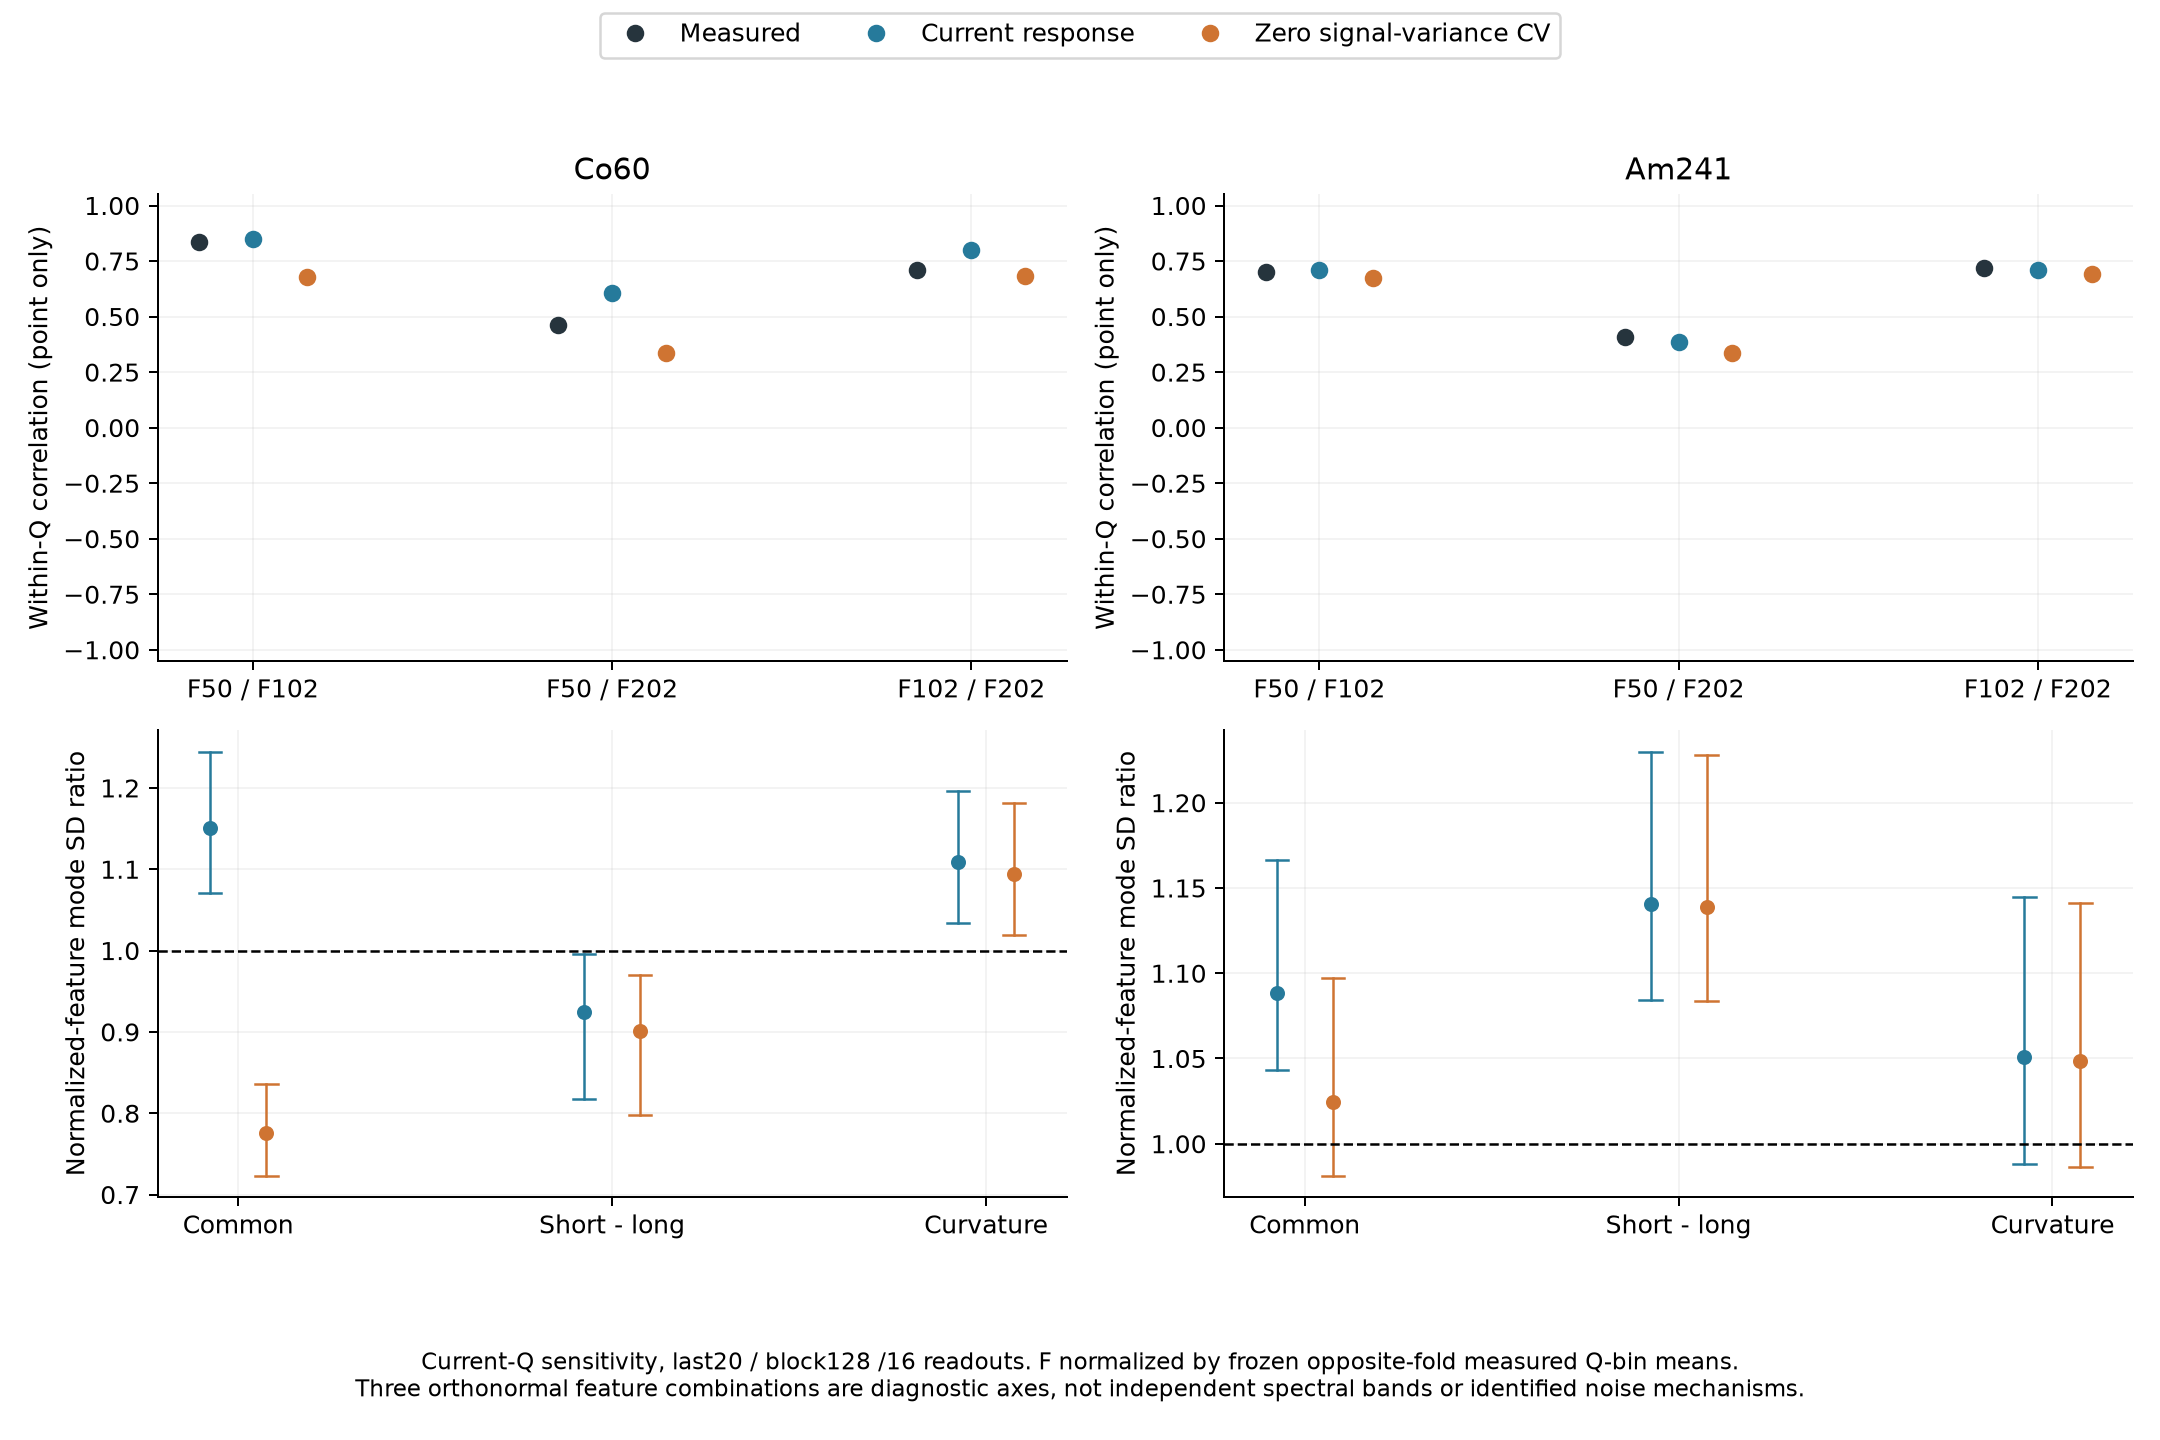

In [4]:
rows=[]
for source,g in repeats.items():
    for v,r in g['conditions']['current_Q']['variants'].items():
        for n in ['F_common_SD_ratio','F_short_long_SD_ratio','F_curvature_SD_ratio','F_covariance_relative_error']:
            rows.append([source,v,n,fmt(r['point'][n]),ci(r['CI95'][n])])
display(Markdown(table(['源','响应','联合指标','点值','条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/charge_scale_joint_modes.png')))

## 4. 一个方差方向能否同时满足三个尺度？

令当前CV与零CV对照在某尺度的方差为$V_c,V_0$，实测为$V_d$。只在两个已经计算的方差端点之间作代数诊断：

\[
V(\lambda)=V_0+\lambda(V_c-V_0),\qquad
\lambda_s=\frac{V_{d,s}-V_{0,s}}{V_{c,s}-V_{0,s}}.
\]

λ=0/1分别是零CV/当前响应，超出[0,1]的值原样报告；分母近零则不可估计。配对报告λ50−λ202等差值，判断各尺度对**这条方差直线**的要求是否不同。这里不假设中间原生CV真的遵循这条直线，不将λ换算成器件CV，也不能由此排除所有非线性响应。相关定位、电荷选择和随机归一化都可能造成非线性。


|源|Q条件|λ50|λ102|λ202|λ50−λ202配对范围|
|---|---|---|---|---|---|
|Co60|original_Q|1.109|0.4572|-0.1016|[0.9701, 1.682] (512/512)|
|Co60|retained_original_Q|1.108|0.4545|-0.1055|[0.9663, 1.68] (512/512)|
|Co60|current_Q|1.102|0.4512|-0.1018|[0.9613, 1.672] (512/512)|
|Am241|original_Q|1.313|-0.618|-5.179|[4.379, 9.29] (512/512)|
|Am241|retained_original_Q|1.44|-0.5147|-5.025|[4.39, 9.331] (512/512)|
|Am241|current_Q|1.427|-0.5508|-5.092|[4.531, 9.35] (512/512)|

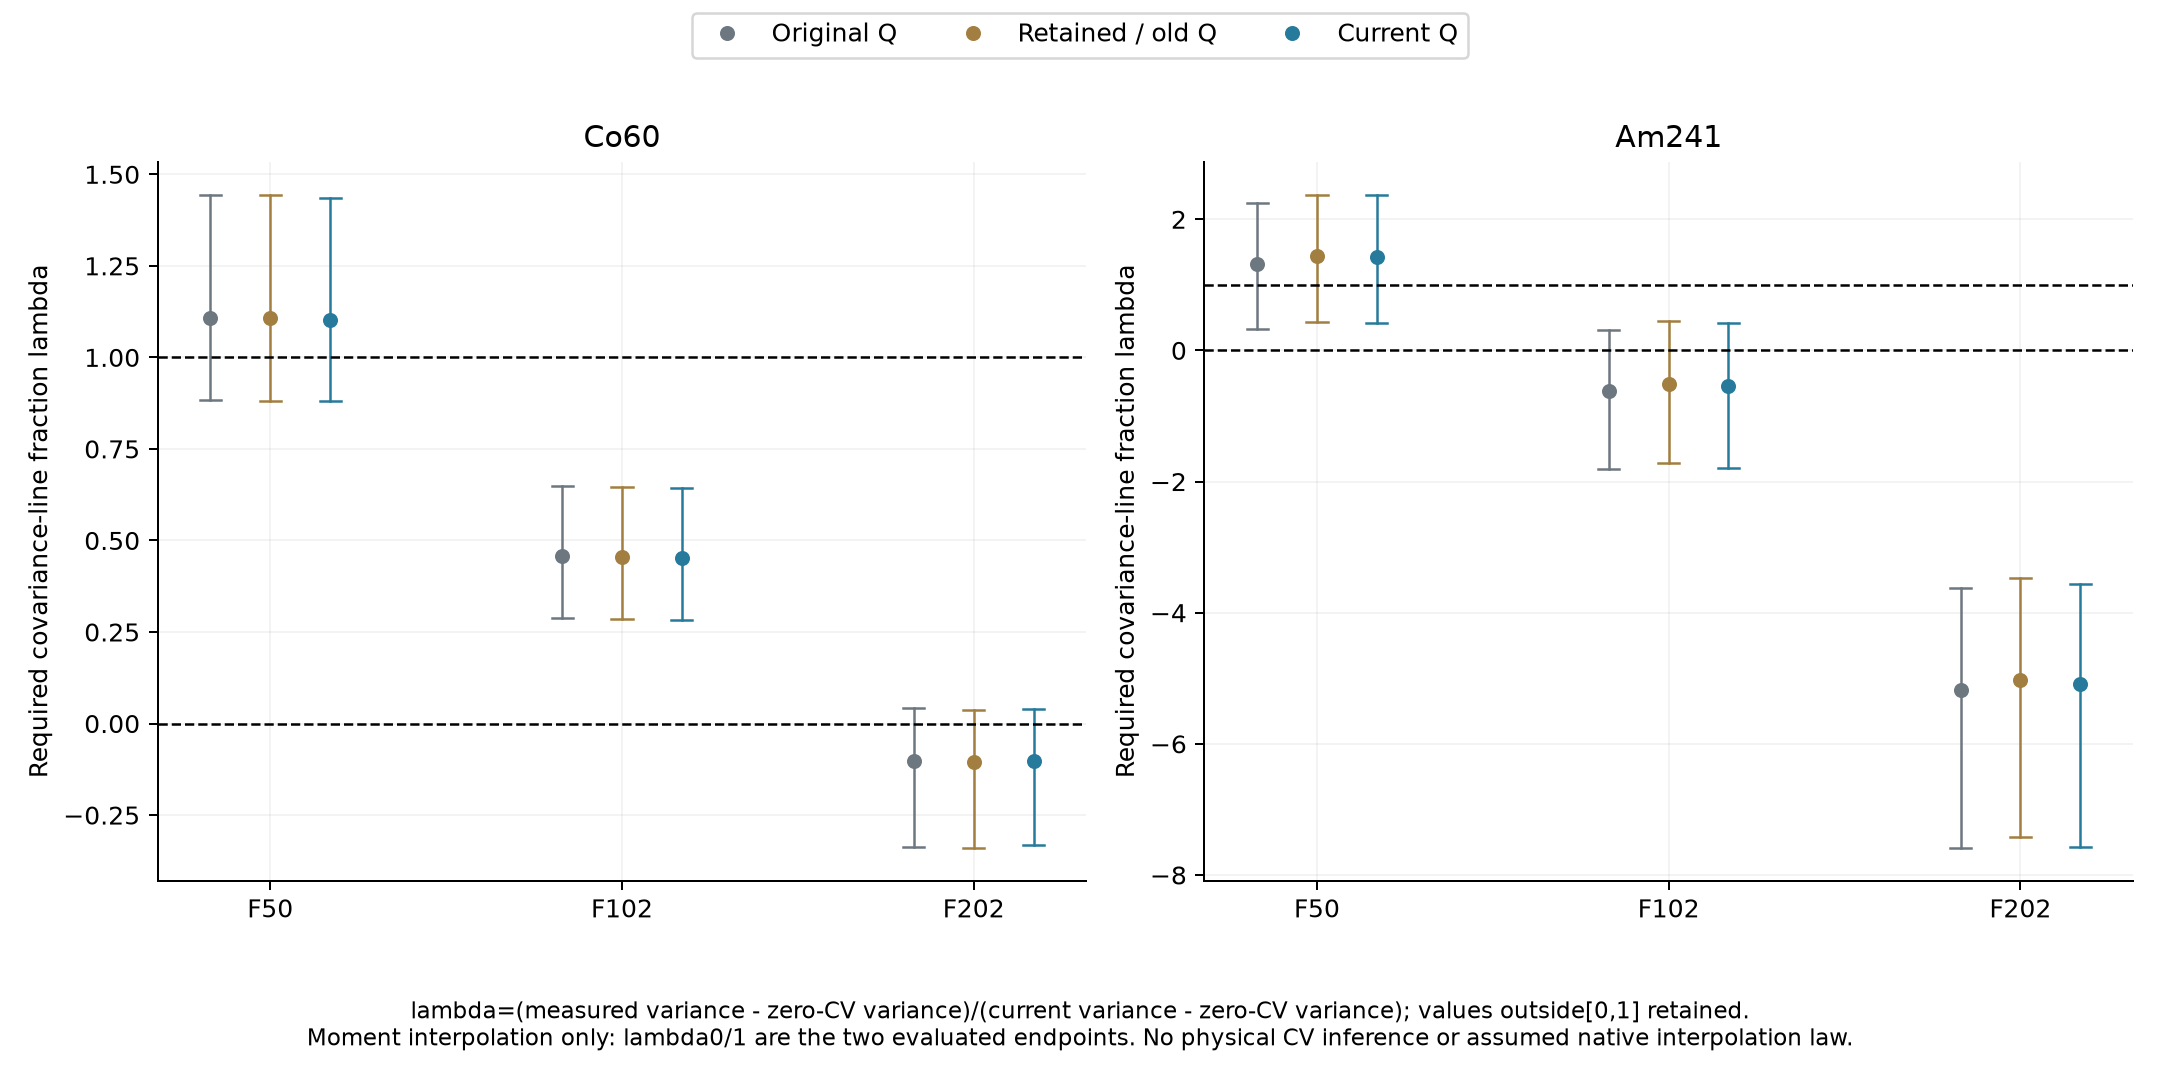

In [5]:
rows=[]
for source,g in repeats.items():
    for c,item in g['conditions'].items():
        r=item['interpolation'];rows.append([source,c,*[fmt(r['point'][f'lambda_F{s}']) for s in [50,102,202]],ci(r['CI95']['lambda_F50_minus_F202'])])
display(Markdown(table(['源','Q条件','λ50','λ102','λ202','λ50−λ202配对范围'],rows)))
display(Image(filename=str(OUT/'figures/charge_variance_line.png')))

## 5. 采集段检查与平均波形

全部前/中/晚段、块64/128都保留原单次读出的配对分析。平均波形使用基线扣除ADC，不逐事件缩放幅度；重分箱后均值的变化是事件组成/权重变化，不是重新调参。零CV对照也没有根据本轮结果重拟合。


|条件|原Q F202比|当前Q F202比|配对变化范围|原Q均ADC相对L2|当前Q均ADC相对L2|
|---|---|---|---|---|---|
|run3_first60_B64|1.114|1.115|[-0.002259, 0.004266] (512/512)|0.03056|0.03043|
|run3_first60_B128|1.115|1.117|[-0.0004331, 0.004773] (512/512)|0.03054|0.03042|
|run3_middle20_B64|1.093|1.095|[-0.001909, 0.005614] (512/512)|0.02951|0.02933|
|run3_middle20_B128|1.099|1.103|[-0.0003488, 0.008312] (512/512)|0.02933|0.0291|
|run3_last20_B64|1.226|1.228|[-0.001397, 0.004768] (512/512)|0.02975|0.02965|
|run3_last20_B128|1.232|1.233|[-0.003353, 0.005065] (512/512)|0.02997|0.02984|
|run12_first60_B64|1.027|1.022|[-0.01199, 0.001507] (512/512)|0.01253|0.01345|
|run12_first60_B128|0.988|0.9858|[-0.007352, 0.002389] (512/512)|0.01249|0.01326|
|run12_middle20_B64|1.107|1.104|[-0.02555, 0.02526] (512/512)|0.01278|0.01419|
|run12_middle20_B128|1.074|1.057|[-0.03564, -0.004044] (512/512)|0.01269|0.01411|
|run12_last20_B64|1.181|1.173|[-0.0311, 0.01967] (512/512)|0.0159|0.01645|
|run12_last20_B128|1.201|1.185|[-0.03617, -0.0007559] (512/512)|0.01597|0.01653|

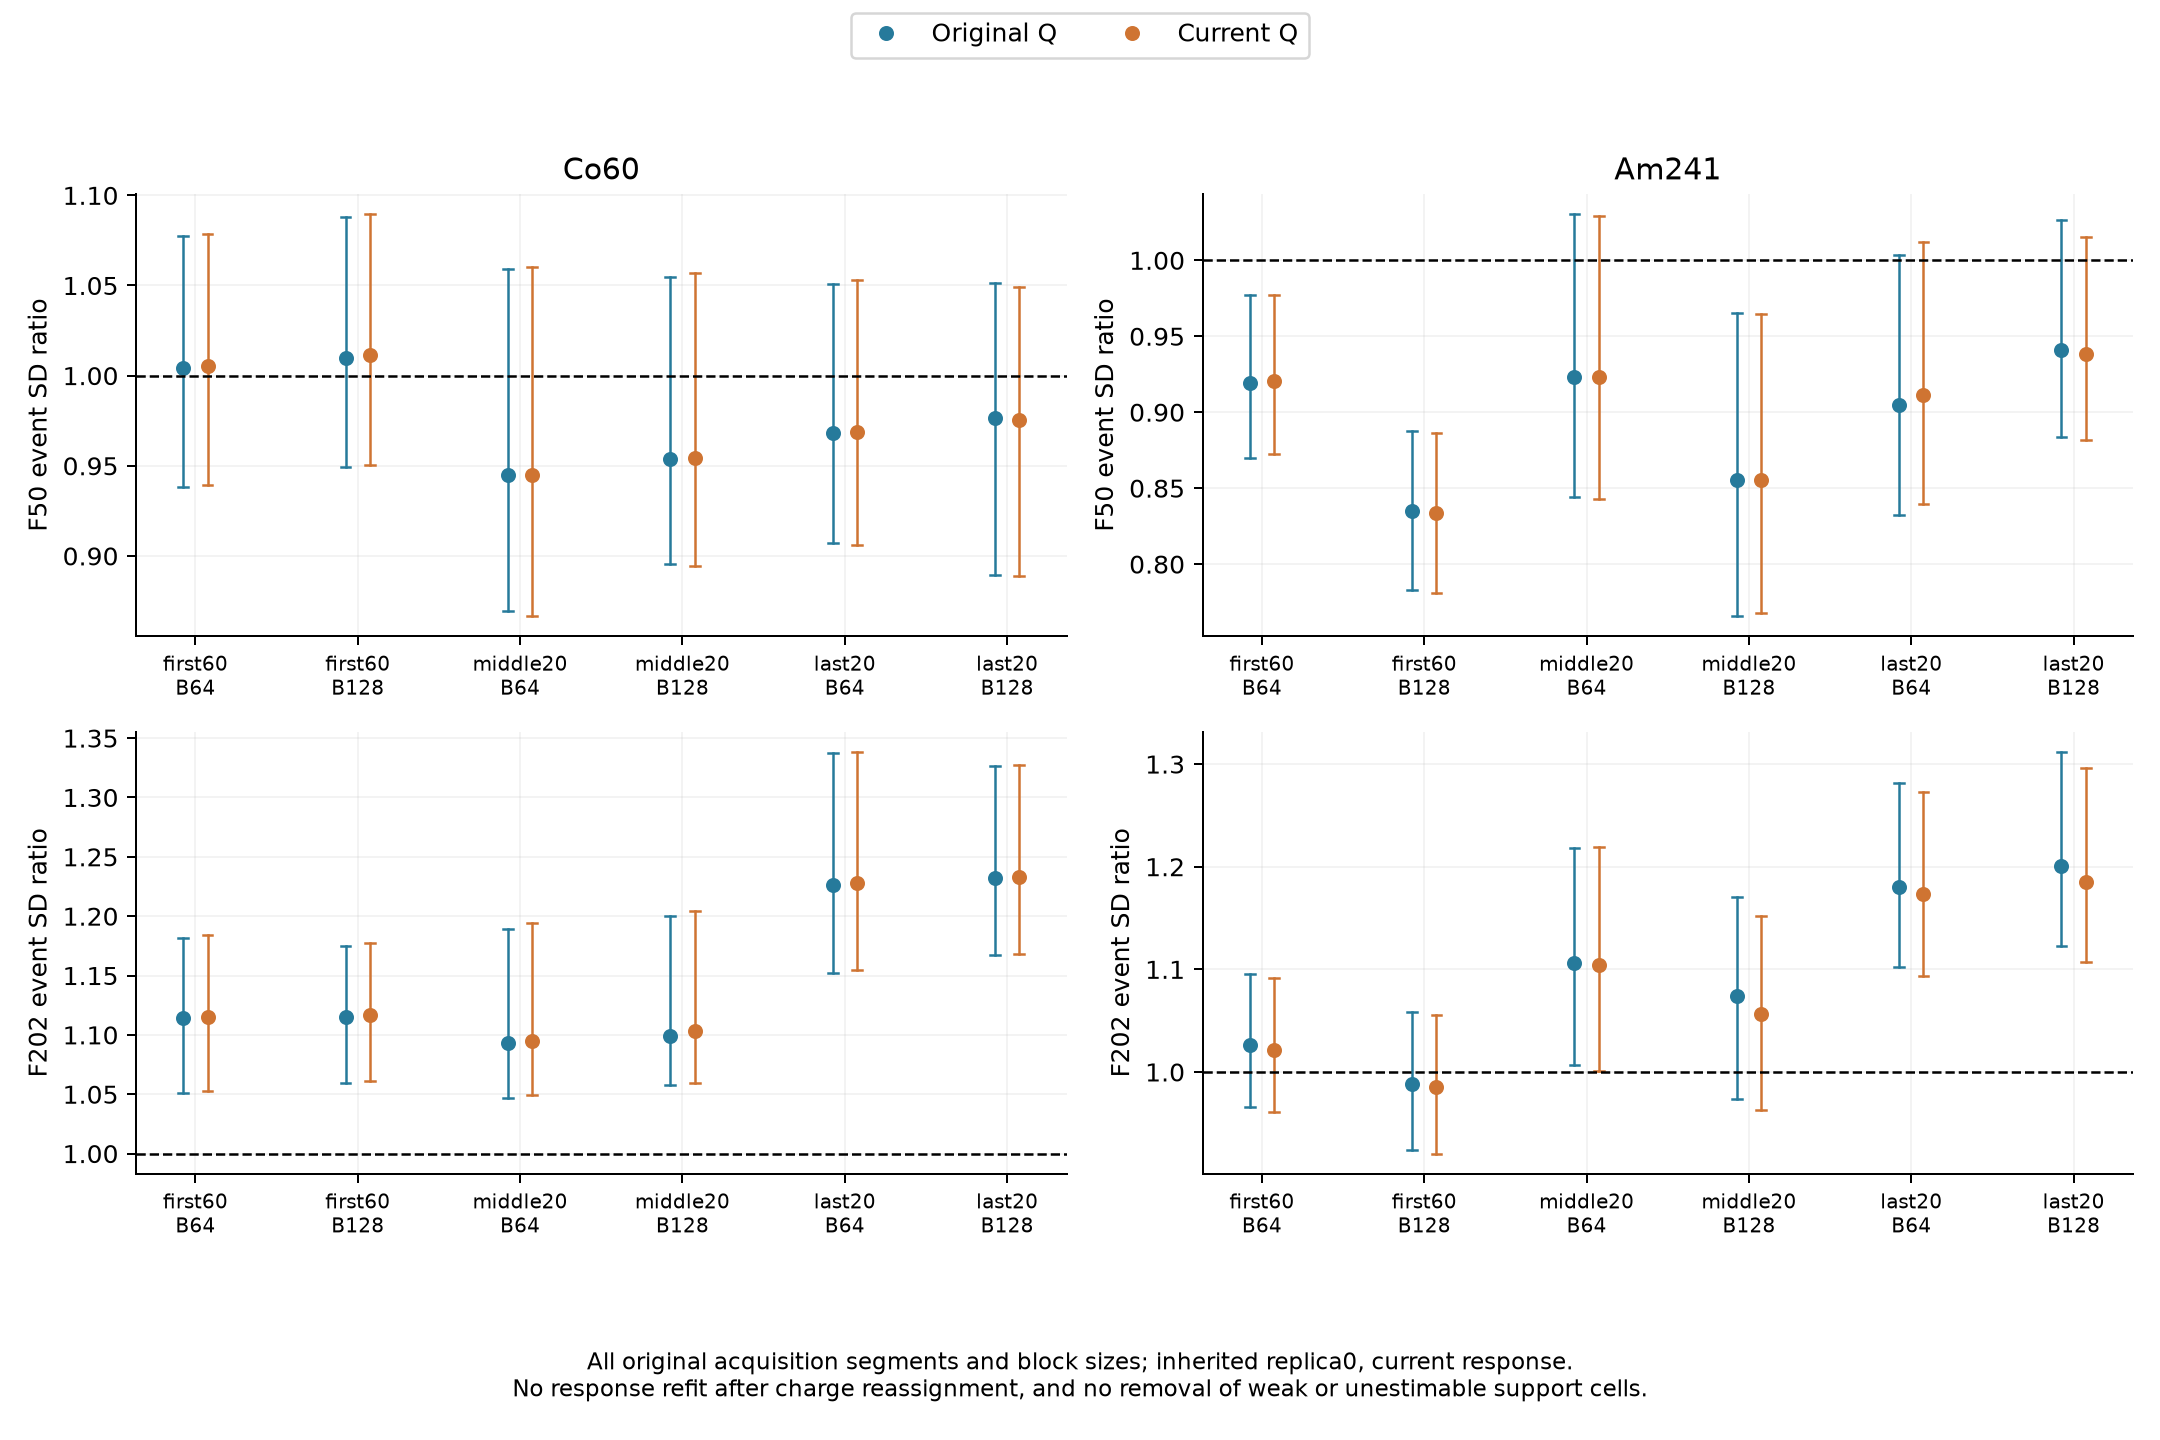

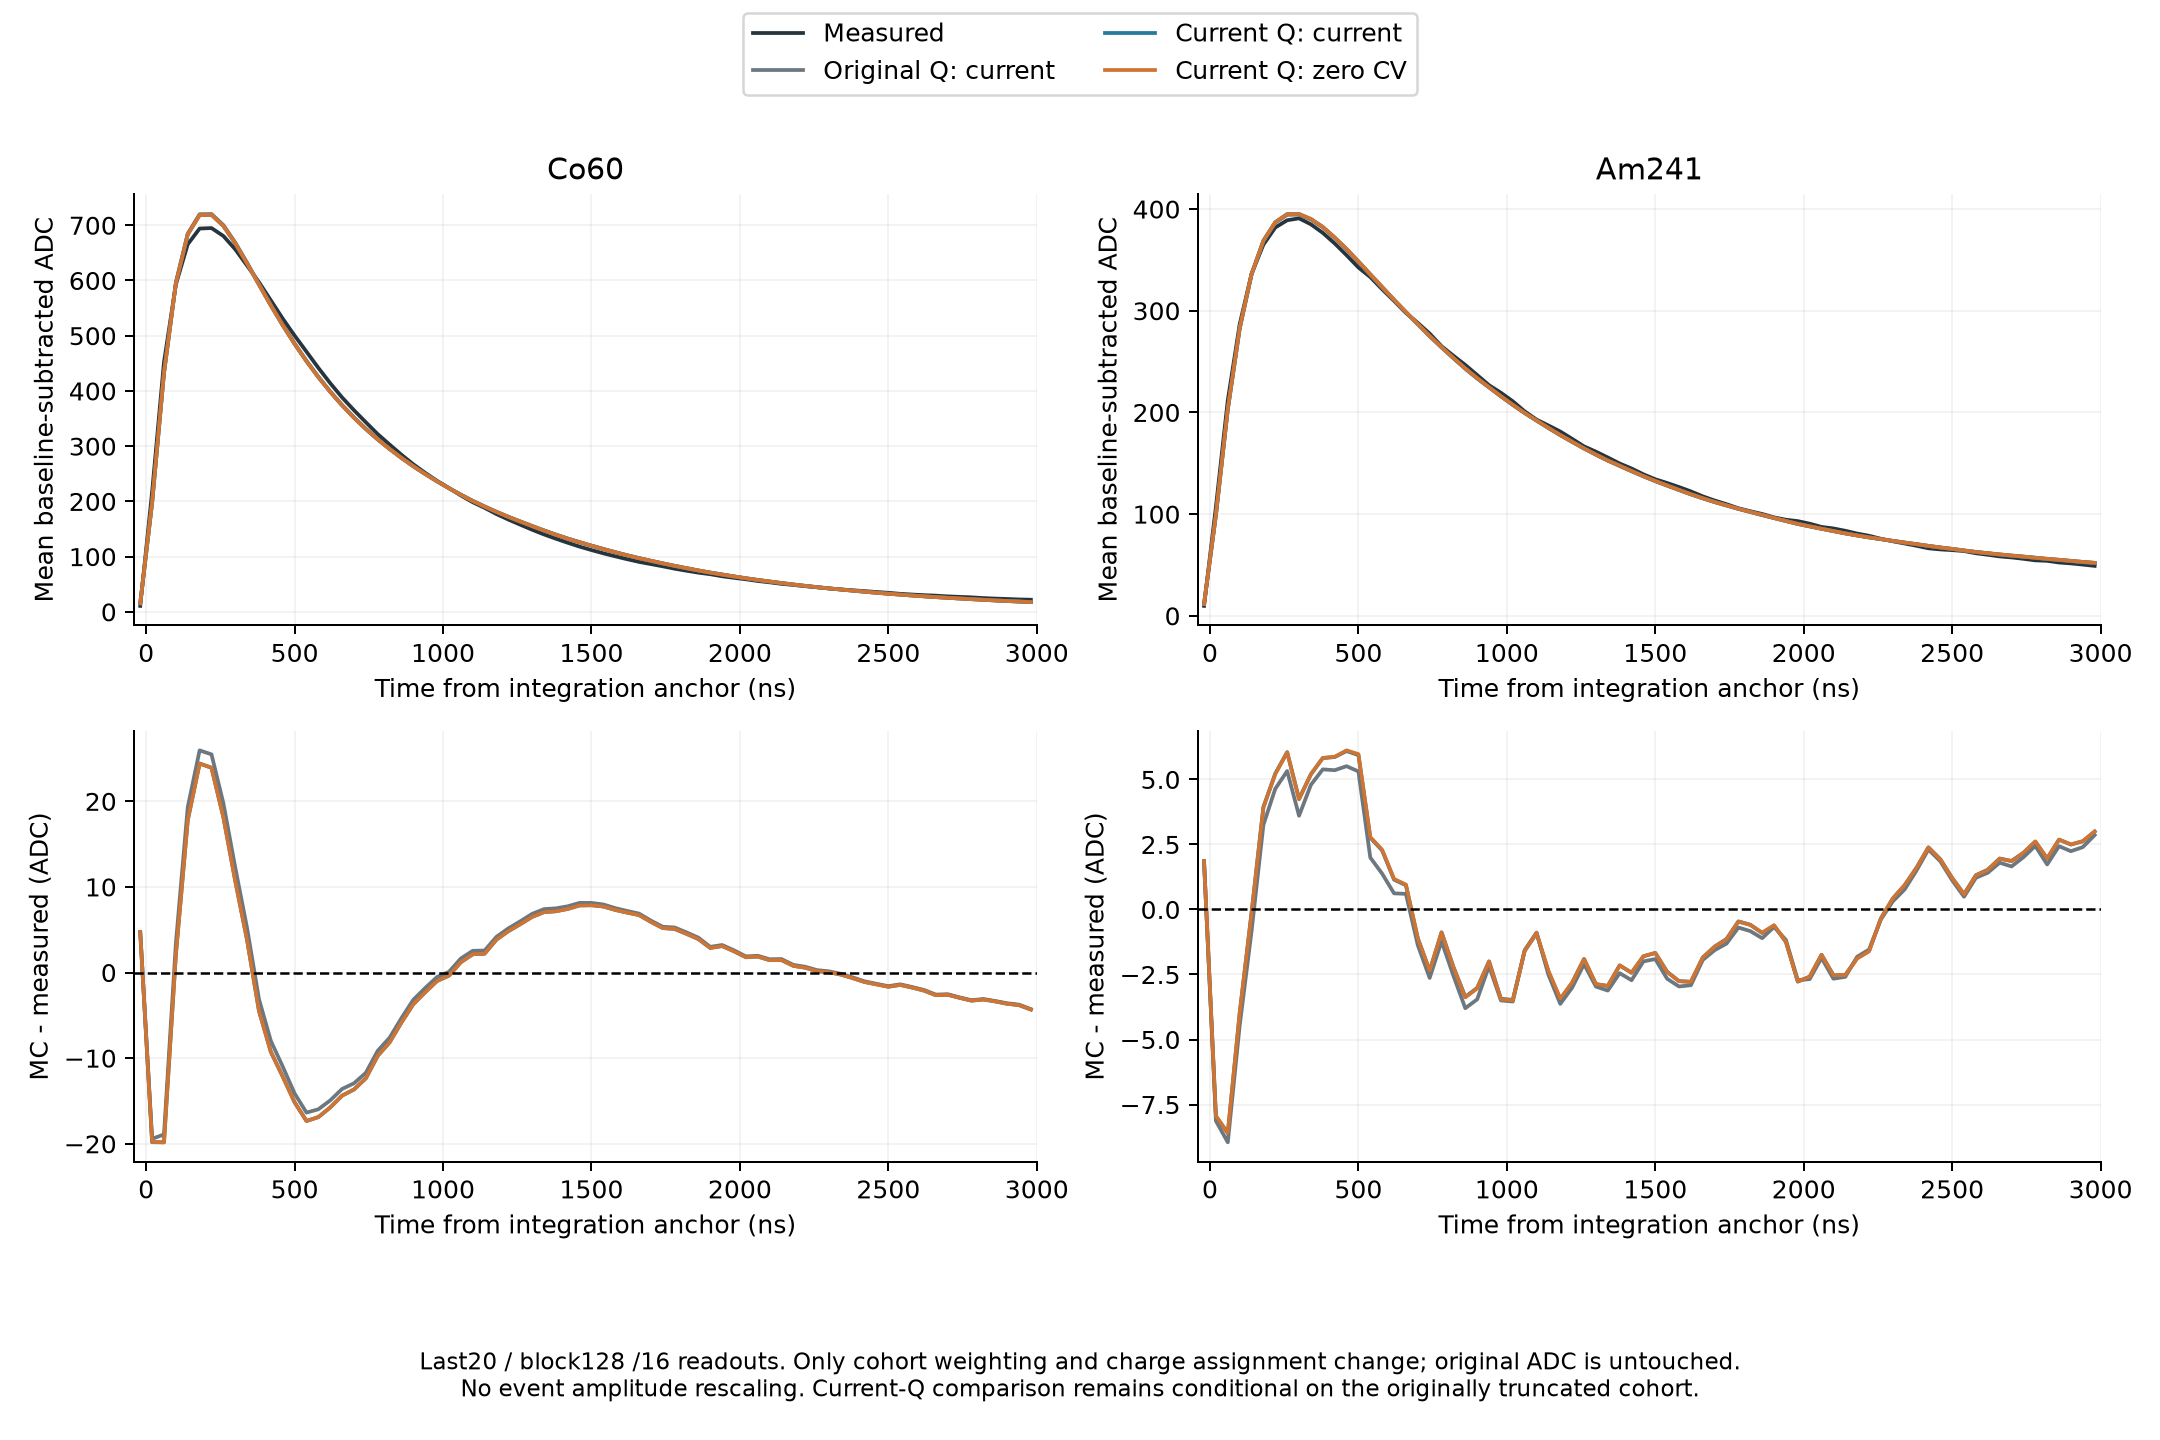

**下一步：**先从完整可用母事件池核查当前读出选择的入口/出口，避免原电荷截断影响；再以F三尺度协方差及差分组合为约束，检验能分别控制尺度相关波动的最小噪声模型。保持平均ADC、PID协方差和分布宽度约束，候选通过后再冻结独立输运验证。

边界：本轮只改变原有限队列中的电荷条件，原范围之外的母事件不能重新进入；并未完成当前触发/质量选择和探测效率验证。

边界：所有参考均值、响应、PCA与Q半箱目标冻结，实验及模拟池都已参与探索；512次条件区间不含重拟合、系统误差或多重比较校正。

边界：每次读出先分别按当前Q重权，再平均协方差；重复作为同一母事件整体抽样。权重随噪声变化后不套用旧的固定权重母事件内/间分解。

边界：F50/F102/F202是相关的波动统计；正交组合只是特征轴，不能解释为相互独立频带或已辨识的微观噪声。

边界：λ是方差端点的代数插值比例，越界值和不稳定区间原样报告。未证明原生CV与此插值线性，不能据此推断物理CV或排除所有非线性模型。

边界：Am源含α及γ/电子成分。来源和主带不提供实验粒子真值；本轮不更新实验ROC或宣称PID全面一致。

In [6]:
rows=[]
for context,g in points.items():
    old=g['conditions']['original_Q']['variants']['current'];new=g['conditions']['current_Q']['variants']['current']
    rows.append([context,fmt(old['point']['F202_SD_ratio']),fmt(new['point']['F202_SD_ratio']),ci(new['change_from_original_Q']['CI95']['F202_SD_ratio']),
                 fmt(old['point']['mean_ADC_relative_L2']),fmt(new['point']['mean_ADC_relative_L2'])])
display(Markdown(table(['条件','原Q F202比','当前Q F202比','配对变化范围','原Q均ADC相对L2','当前Q均ADC相对L2'],rows)))
display(Image(filename=str(OUT/'figures/charge_segment_checks.png')))
display(Image(filename=str(OUT/'figures/charge_mean_waveforms.png')))
display(Markdown('**下一步：**'+d['next_work_zh']))
for limit in d['limitations_zh']:display(Markdown('边界：'+limit))

## 6. 记录与复现

`protocol.json`冻结505个输入哈希、代码、三种Q条件、正交组合、16次重复与512次配对计数口径；`references/`保存对折实测尺度均值及训练ID。`point_evaluation/`与`repeat_evaluation/`保存完整协方差、指标、原支持计数、跨箱矩阵和全部抽样对比。

`point_table.csv`有72行，`repeat_table.csv`有12行，`variance_line_table.csv`有42行，`migration_table.csv`有100行。`verification.json`检查原指标闭合、直接加权协方差、原生电荷一致性、条件区间及笔记；`record.json`封存输出和源码快照。

流程为`prepare_charge_scales.py` → `analyze_charge_scales.py points --workers 2` → `analyze_charge_scales.py repeats --workers 2` → `report_charge_scales.py` → 本笔记生成器 → `verify_charge_scales.py`及`--archive`。完整重跑须在新结果目录冻结方案。旧档案保持原样，本轮没有联网或修改共享文献库。
